# Fundamentals of Machine Learning - Exercise 2
* The aim of the exercise is to learn basic techniques for visualization creation and interpretation using Matplotlib and Seaborn libraries.

![meme02](https://github.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/blob/master/images/fml_02_meme_02.png?raw=true)

# Exploratory data analysis

Data source: https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data

Important attributes description:
* SalePrice: The property's sale price in dollars. This is the target variable that you're trying to predict.
* MSSubClass: The building class
* BldgType: Type of dwelling
* HouseStyle: Style of dwelling
* OverallQual: Overall material and finish quality
* OverallCond: Overall condition rating
* YearBuilt: Original construction date
* Heating: Type of heating
* CentralAir: Central air conditioning
* GrLivArea: Above grade (ground) living area square feet
* BedroomAbvGr: Number of bedrooms above basement level

## Import used packages

In [1]:
import pandas as pd # dataframes
import numpy as np # matrices and linear algebra
import matplotlib.pyplot as plt # plotting
import seaborn as sns # another matplotlib interface - styled and easier to use

## Load the data into the Pandas DataFrame - in our case it is a csv file
* https://raw.githubusercontent.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/master/datasets/zsu_cv1_data.csv

In [2]:
url = "https://raw.githubusercontent.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/master/datasets/zsu_cv1_data.csv"

df = pd.read_csv(url)

## Price is the most interisting attribute in our dataset, let's take a look on its distribution
- SalePrice

## Vizualize house prices in form of histogram
- What does it tell us about the prices?

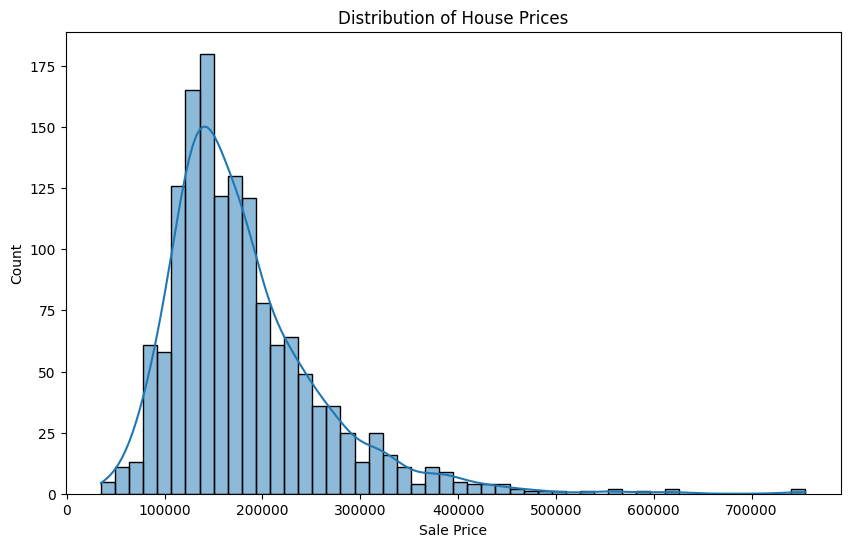

In [3]:
# Histogram of house prices
plt.figure(figsize=(10,6))
sns.histplot(df['SalePrice'], bins=50, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price")
plt.ylabel("Count")
plt.show()


### Modify bins
- Perhaps we want to visualize the histogram with more dense or coarse bins
- *bins* attribute

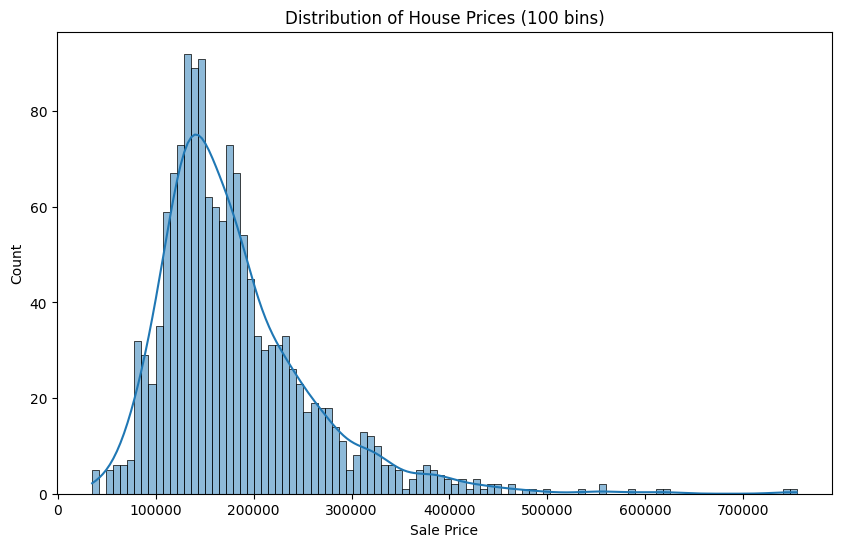

In [4]:
# Histogram with different number of bins
plt.figure(figsize=(10,6))
sns.histplot(df['SalePrice'], bins=100, kde=True)  # třeba 100 místo 50

plt.title("Distribution of House Prices (100 bins)")
plt.xlabel("Sale Price")
plt.ylabel("Count")
plt.show()


### Use quartiles (Q1, Q3) for highlighting most common price range in histogram

* Check functions *describe* and *quantile* over price column

In [5]:
# Basic statistics
print(df['SalePrice'].describe())



count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [6]:

df.SalePrice.quantile(0.5)

np.float64(163000.0)

## 🔎 What can we say about prices based on the quantiles?
### Use function *axvline* from Matplotlib to draw vertical lines at the quartile positions

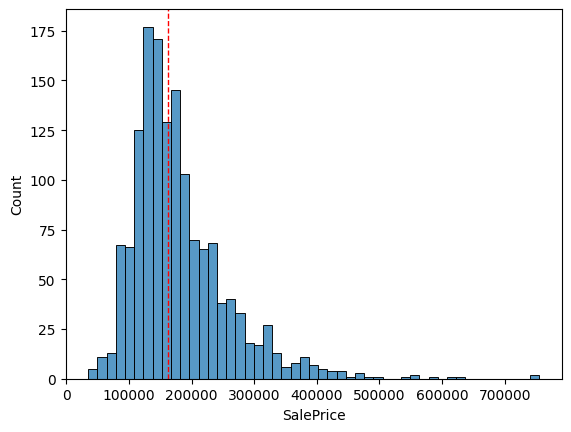

In [7]:
sns.histplot(df.SalePrice)
plt.axvline(df.SalePrice.quantile(0.5), color='red', linestyle='dashed', linewidth=1)

## 📊 Let's add more complexity to histogram vizualizations. 
### Does price change for different values of GaragaFinish attribute?

### GarageFinish: Interior finish of the garage
- Fin	Finished
- RFn	Rough Finished	
- Unf	Unfinished
- NA	No Garage

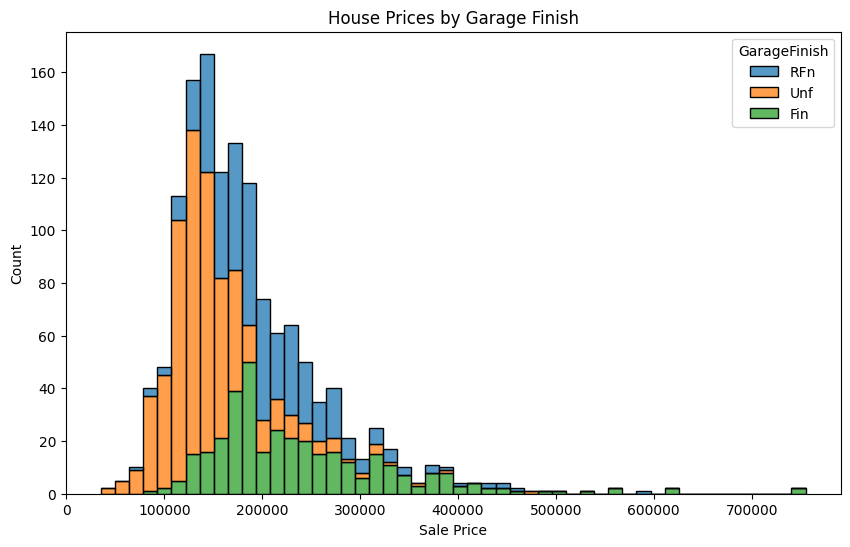

In [8]:
# Compare SalePrice distribution for different GarageFinish categories
plt.figure(figsize=(10,6))
sns.histplot(data=df, x="SalePrice", hue="GarageFinish", bins=50, kde=False, multiple="stack")

plt.title("House Prices by Garage Finish")
plt.xlabel("Sale Price")
plt.ylabel("Count")
plt.show()


### 💡 We can see that houses with no garage are somehow missing
- The no garage houses have a *nan* value in the feature so they are not plotted

### Fill nan values with 'NoGarage' string

In [9]:
# Replace NaN in GarageFinish with 'NoGarage'
df["GarageFinish"] = df["GarageFinish"].fillna("NoGarage")

df["GarageFinish"].value_counts()


GarageFinish
Unf         605
RFn         422
Fin         352
NoGarage     81
Name: count, dtype: int64

### Take a look at the histogram again

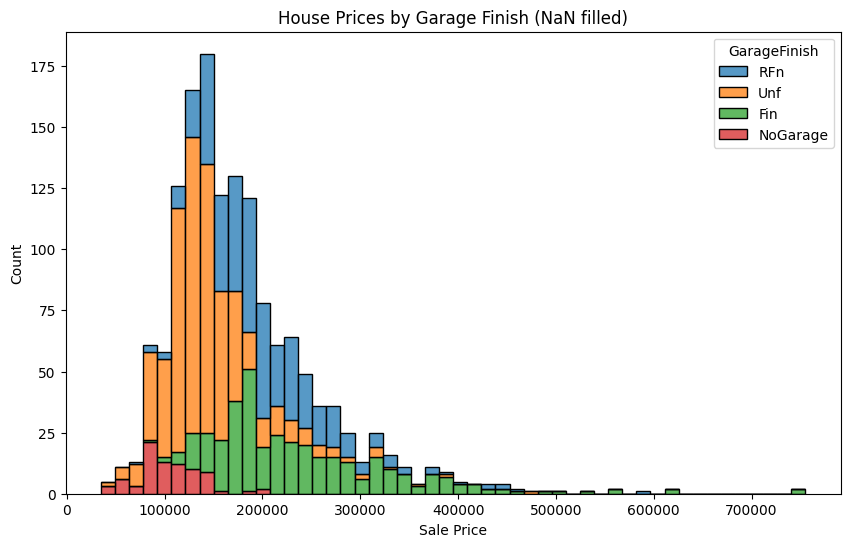

In [10]:
# Histogram of SalePrice by GarageFinish (with NoGarage included)
plt.figure(figsize=(10,6))
sns.histplot(data=df, x="SalePrice", hue="GarageFinish", bins=50, multiple="stack")

plt.title("House Prices by Garage Finish (NaN filled)")
plt.xlabel("Sale Price")
plt.ylabel("Count")
plt.show()


## 💡 Sometimes the histograms distinguished by colors are not easily redeable
- We can use *col* attribute to automatically plot every histogram on its own canvas

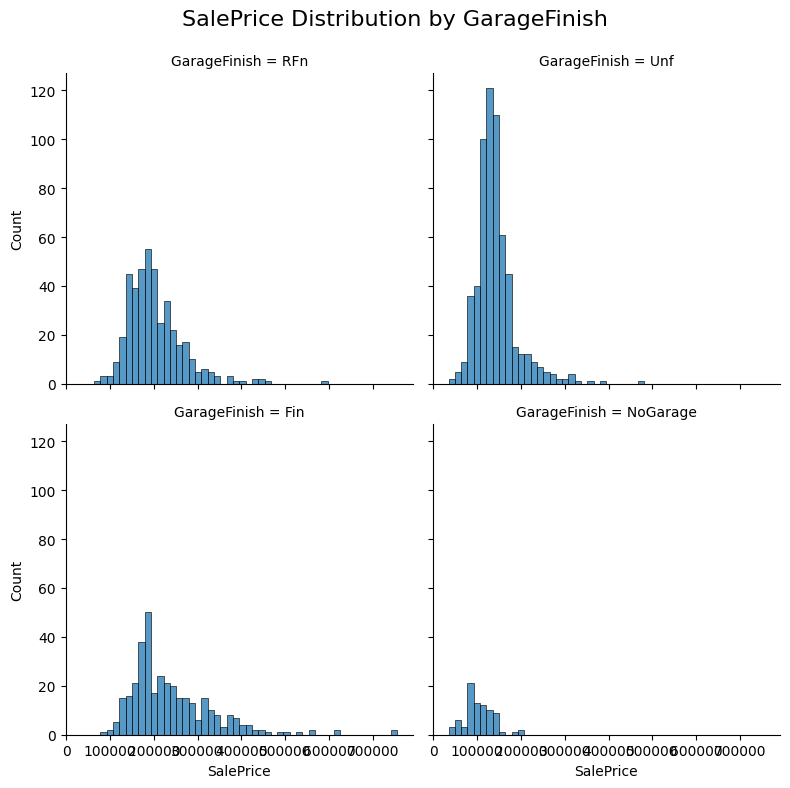

In [11]:
# Separate histograms for each GarageFinish category
sns.displot(data=df, x="SalePrice", col="GarageFinish", col_wrap=2, bins=50, height=4)

plt.subplots_adjust(top=0.9)
plt.suptitle("SalePrice Distribution by GarageFinish", fontsize=16)
plt.show()


# 📊 Another very useful tecnique for the numerical features distributions are boxplots
- 🔎 Did you see any of these before?

- 🔎 How should we read boxplots?
    - **Quartiles**
    - **Median**
    - Box size
    - **Outliers and IQR**
    - Min/max - with or without outliers

### Plot only the *SalePrice* using boxplot

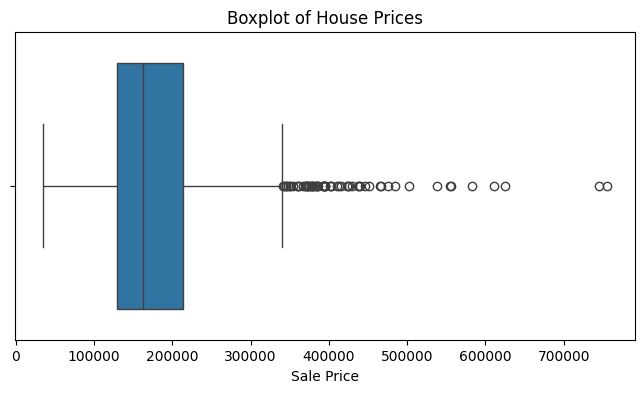

In [12]:
# Boxplot of SalePrice
plt.figure(figsize=(8,4))
sns.boxplot(x=df["SalePrice"])

plt.title("Boxplot of House Prices")
plt.xlabel("Sale Price")
plt.show()


## Let's take a look at the *SalePrice* for different *BldgType* values 
- 🔎 What can we say about the prices?

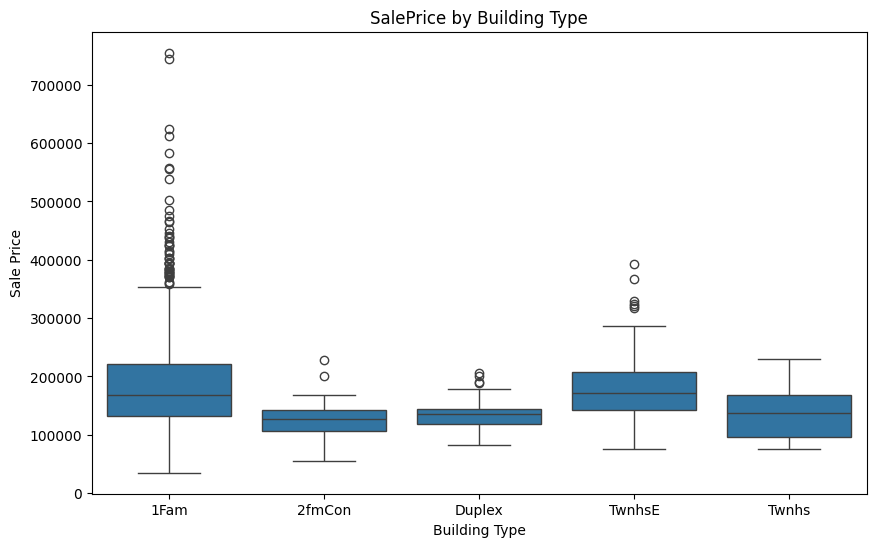

In [13]:
# Boxplot SalePrice grouped by BldgType
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x="BldgType", y="SalePrice")

plt.title("SalePrice by Building Type")
plt.xlabel("Building Type")
plt.ylabel("Sale Price")
plt.show()


## We can do the same for *GrLivArea*

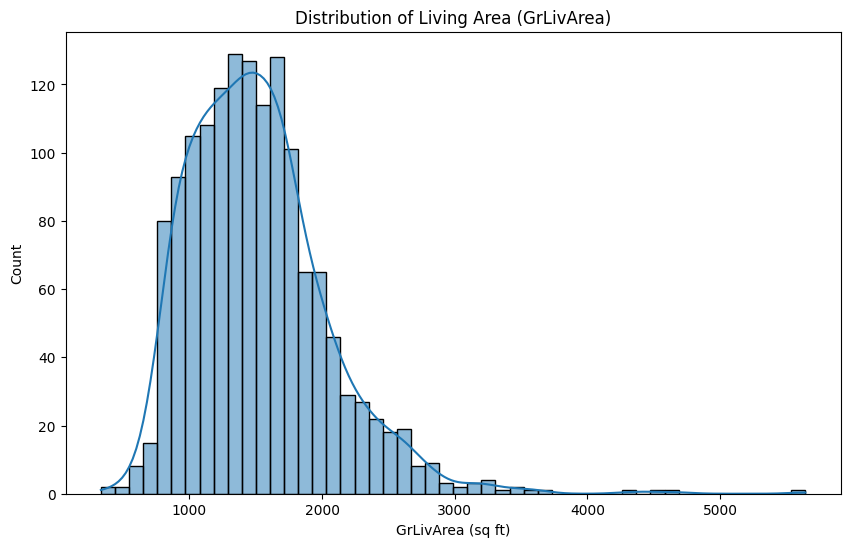

In [14]:
# Distribution of GrLivArea
plt.figure(figsize=(10,6))
sns.histplot(df["GrLivArea"], bins=50, kde=True)

plt.title("Distribution of Living Area (GrLivArea)")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("Count")
plt.show()


## Let's take a look at the *GrLivArea* for different *BldgType* values 
- 🔎 What can we say about the GrLivArea?

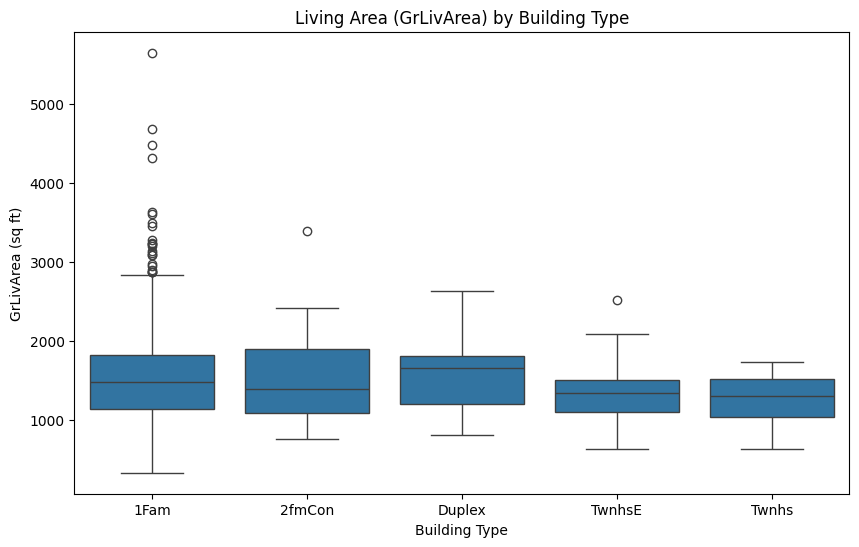

In [15]:
# Boxplot GrLivArea grouped by BldgType
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x="BldgType", y="GrLivArea")

plt.title("Living Area (GrLivArea) by Building Type")
plt.xlabel("Building Type")
plt.ylabel("GrLivArea (sq ft)")
plt.show()


# 📊 Scatter plots are commonly used for visualizing two numerical variables

### We can use standard *scatterplot* with *BldgType* as a *hue* so we can better grasp the relationship between *GrLivArea* and *SalePrice*
* Try to set *alpha* parameter for opacity settings

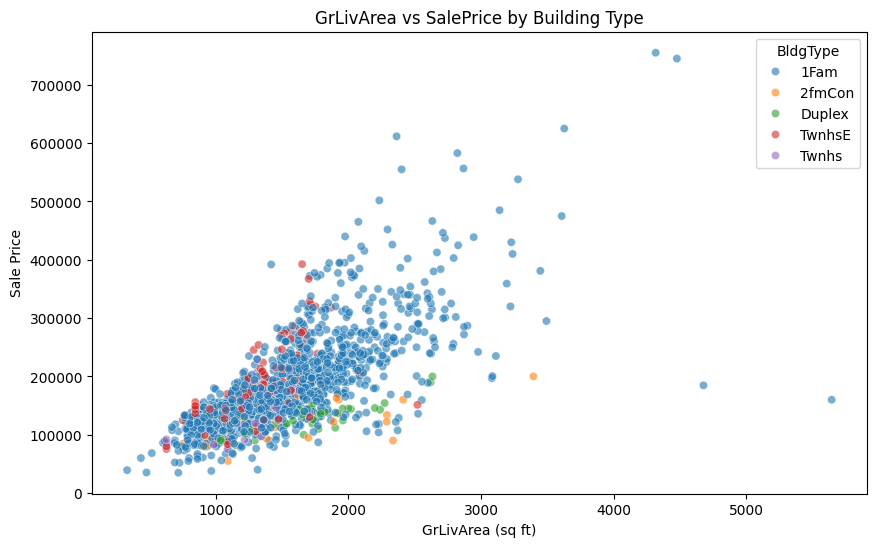

In [16]:
# Scatterplot of Living Area vs. Sale Price
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", hue="BldgType", alpha=0.6)

plt.title("GrLivArea vs SalePrice by Building Type")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("Sale Price")
plt.show()


### We can see there are some outliers in the data, let's zoom only to area without them, how can we filter the data?

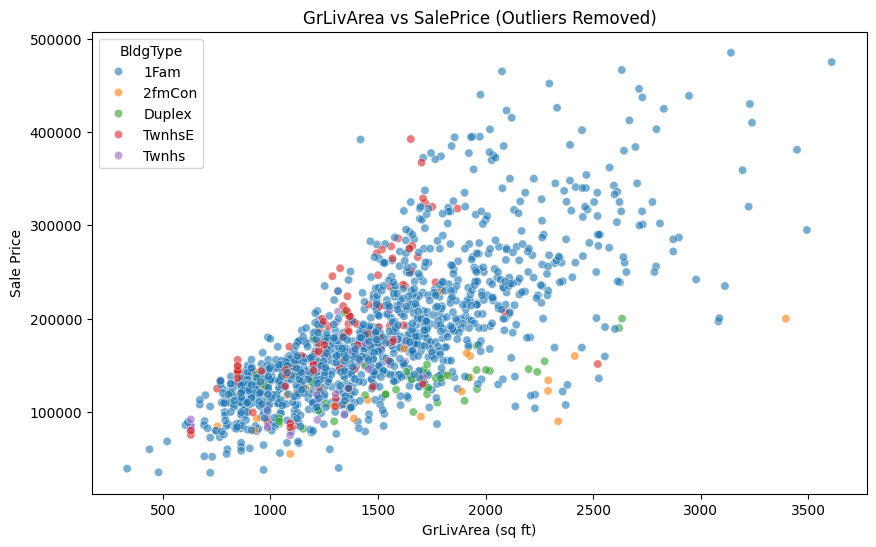

In [17]:
# Remove extreme outliers for clearer plot
filtered = df[(df["GrLivArea"] < 4500) & (df["SalePrice"] < 500000)]

plt.figure(figsize=(10,6))
sns.scatterplot(data=filtered, x="GrLivArea", y="SalePrice", hue="BldgType", alpha=0.6)

plt.title("GrLivArea vs SalePrice (Outliers Removed)")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("Sale Price")
plt.show()


# We have an information about a month and a year for the sold houses.
## 🔎 Can you vizualize what was the average price of the house by quarters?

* We need to create a new column **YearQuarterSold** with merged Year and Quarter information in this pattern: '2010-1','2010-2' and so on first
    * We can map the values using the *apply* function or use string concatenation directly
* 💡 If you need to change data type of the columns, you can use *astype*

In [18]:
# Create YearQuarterSold column (e.g. '2010-Q1')
df_full = df.copy()

df_full["Year"] = df_full["YrSold"].astype(str)
df_full["Quarter"] = ((df_full["MoSold"] - 1) // 3 + 1).astype(str)
df_full["YearQuarterSold"] = df_full["Year"] + "-Q" + df_full["Quarter"]

df_full[["YrSold", "MoSold", "YearQuarterSold"]].head()


,YrSold,MoSold,YearQuarterSold
0,2008,2,2008-Q1
1,2007,5,2007-Q2
2,2008,9,2008-Q3
3,2006,2,2006-Q1
4,2008,12,2008-Q4


### Compute the average price for the *YearQuarterSold* attribute

In [19]:
# Compute average SalePrice per YearQuarterSold
avg_prices = df_full.groupby("YearQuarterSold")["SalePrice"].mean().reset_index()
avg_prices.head()


,YearQuarterSold,SalePrice
0,2006-Q1,190553.522727
1,2006-Q2,168277.176991
2,2006-Q3,191858.980952
3,2006-Q4,187993.480769
4,2007-Q1,178489.159091


## Vizualize the data using *lineplot*
- In case of xlabels mixing try to tune the *rotation* and *horizontalalignment* parameters

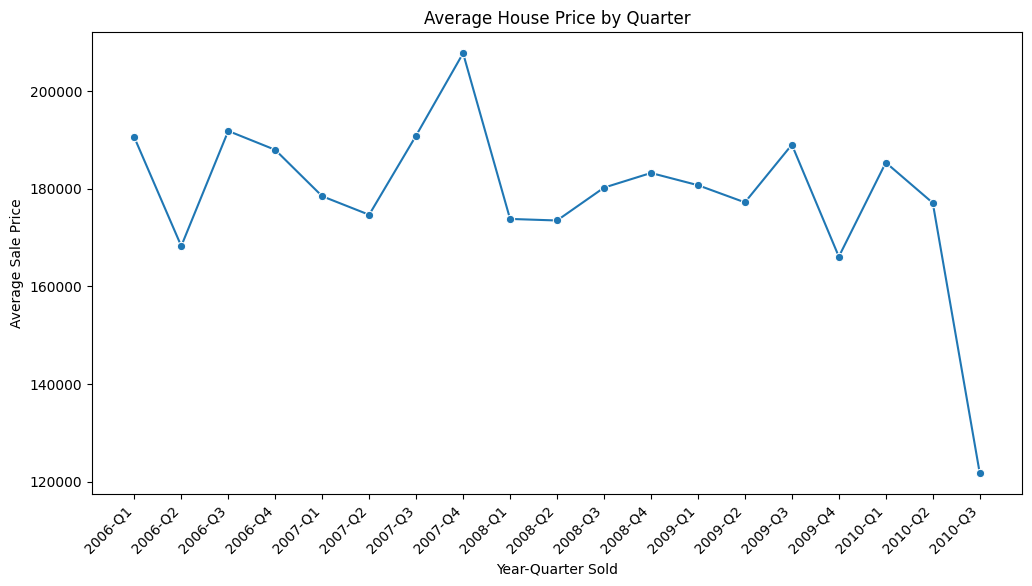

In [20]:
# Lineplot of average SalePrice by YearQuarterSold
plt.figure(figsize=(12,6))
sns.lineplot(data=avg_prices, x="YearQuarterSold", y="SalePrice", marker="o")

plt.xticks(rotation=45, ha="right")
plt.title("Average House Price by Quarter")
plt.xlabel("Year-Quarter Sold")
plt.ylabel("Average Sale Price")
plt.show()


### Add the max, min and median to the plot
- Use *describe* and the [Pandas Melt](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.melt.html) function
    - use YearQuarterSold as an *id_vars*
    - use 'min', 'mean', '50%', 'max' as *value_vars*

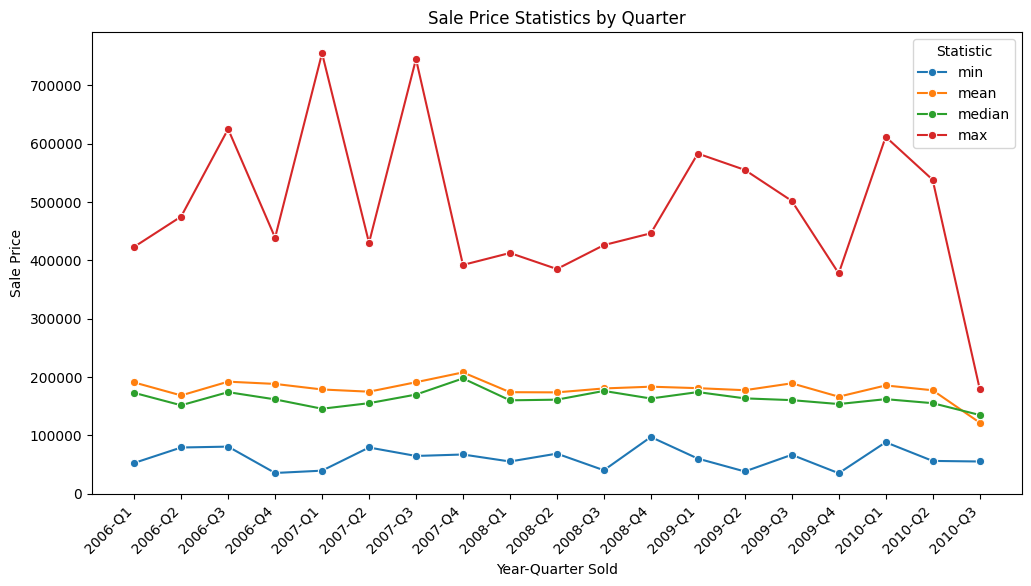

In [21]:
stats = (
    df_full.groupby("YearQuarterSold")["SalePrice"]
    .agg(["min", "mean", "median", "max"])
    .reset_index()
)

stats.head()


# Melt data for easier plotting
stats_melted = stats.melt(id_vars="YearQuarterSold", 
                          value_vars=["min", "mean", "median", "max"], 
                          var_name="Statistic", value_name="SalePrice")

plt.figure(figsize=(12,6))
sns.lineplot(data=stats_melted, x="YearQuarterSold", y="SalePrice", hue="Statistic", marker="o")

plt.xticks(rotation=45, ha="right")
plt.title("Sale Price Statistics by Quarter")
plt.xlabel("Year-Quarter Sold")
plt.ylabel("Sale Price")
plt.show()


![meme01](https://github.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/blob/master/images/fml_02_meme_01.png?raw=true)

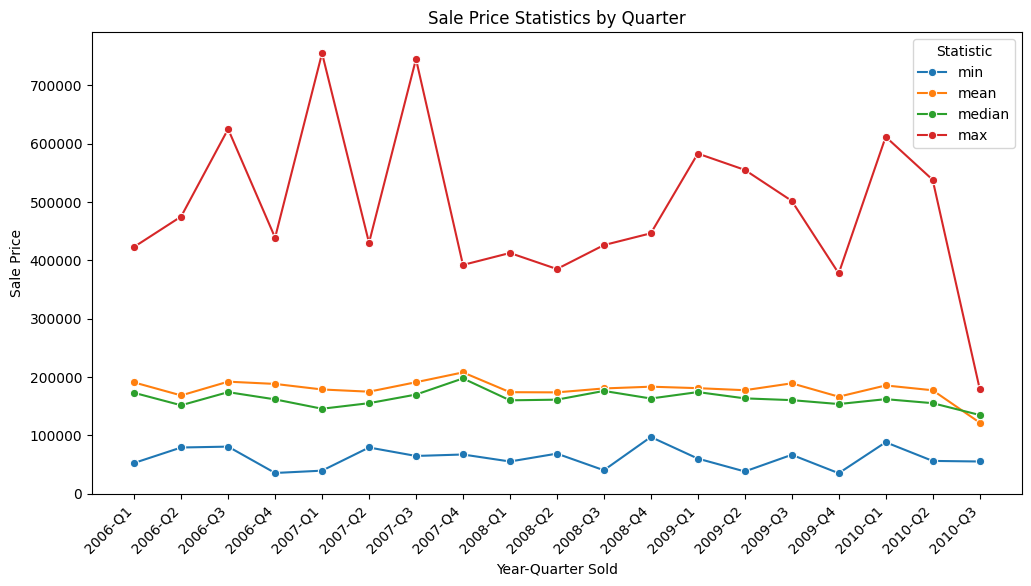

In [22]:
# Aggregate only required statistics
df_agg = (
    df_full.groupby("YearQuarterSold")["SalePrice"]
    .agg(min="min", mean="mean", median="median", max="max")
    .reset_index()
)

# Melt for plotting
df_melt = pd.melt(
    df_agg,
    id_vars=["YearQuarterSold"],
    value_vars=["min", "mean", "median", "max"],
    var_name="Statistic",
    value_name="SalePrice"
)

df_melt.head()


plt.figure(figsize=(12,6))
sns.lineplot(data=df_melt, x="YearQuarterSold", y="SalePrice", hue="Statistic", marker="o")

plt.xticks(rotation=45, ha="right")
plt.title("Sale Price Statistics by Quarter")
plt.xlabel("Year-Quarter Sold")
plt.ylabel("Sale Price")
plt.show()



## What can we say about the minimum and maximum values?
- 💡Take a look at std. deviation

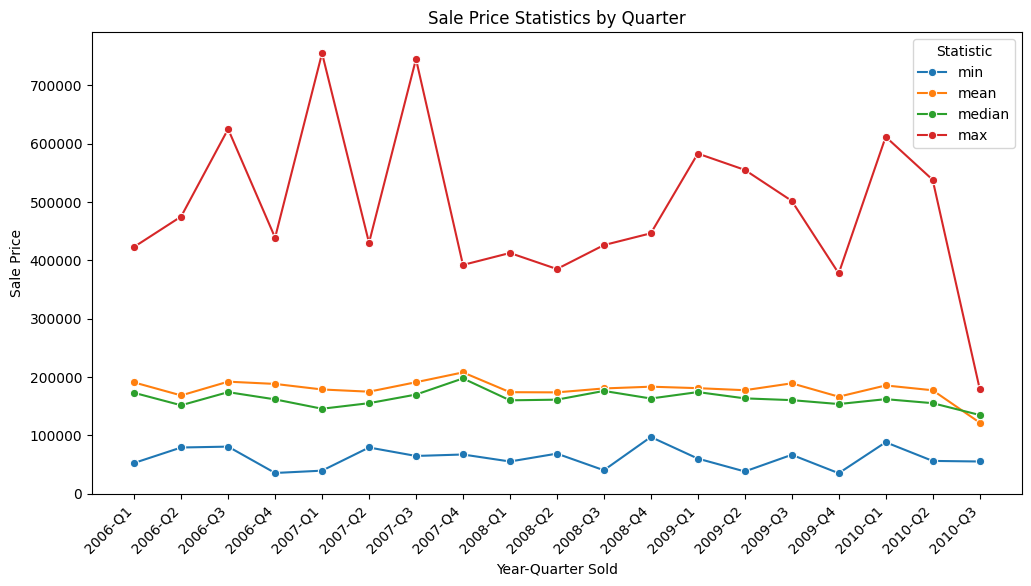

In [23]:
# Aggregate only required statistics
df_agg = (
    df_full.groupby("YearQuarterSold")["SalePrice"]
    .agg(min="min", mean="mean", median="median", max="max")
    .reset_index()
)

# Melt for plotting
df_melt = pd.melt(
    df_agg,
    id_vars=["YearQuarterSold"],
    value_vars=["min", "mean", "median", "max"],
    var_name="Statistic",
    value_name="SalePrice"
)

df_melt.head()


plt.figure(figsize=(12,6))
sns.lineplot(data=df_melt, x="YearQuarterSold", y="SalePrice", hue="Statistic", marker="o")

plt.xticks(rotation=45, ha="right")
plt.title("Sale Price Statistics by Quarter")
plt.xlabel("Year-Quarter Sold")
plt.ylabel("Sale Price")
plt.show()



# We can take a look at number of sold houses for the defined time periods as well
## 📊 We will use standard bar plot
- 🔎 In which quarter were the most houses sold?
- 💡 Fun facts: [https://themortgagereports.com/44135/whats-the-best-time-of-year-to-sell-a-home](https://themortgagereports.com/44135/whats-the-best-time-of-year-to-sell-a-home)

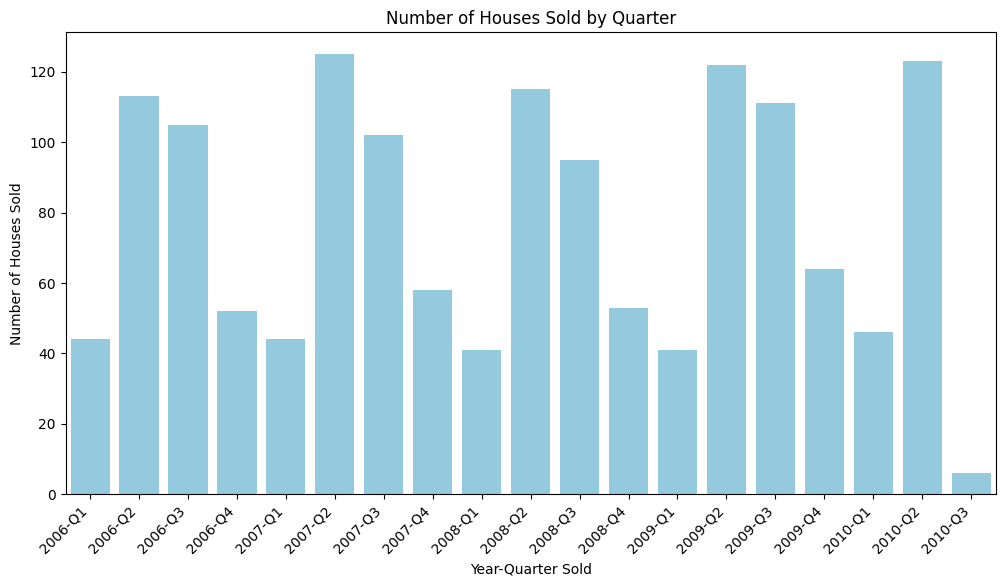

YearQuarterSold
2006-Q1     44
2006-Q2    113
2006-Q3    105
2006-Q4     52
2007-Q1     44
Name: count, dtype: int64

In [24]:
# Count houses sold per quarter
quarter_counts = df_full["YearQuarterSold"].value_counts().sort_index()

plt.figure(figsize=(12,6))
sns.barplot(x=quarter_counts.index, y=quarter_counts.values, color="skyblue")
plt.xticks(rotation=45, ha="right")
plt.title("Number of Houses Sold by Quarter")
plt.xlabel("Year-Quarter Sold")
plt.ylabel("Number of Houses Sold")
plt.show()

quarter_counts.head()




# Tasks (2p)
## ✅ Task 1 - Outlier detection (1p)
- We need to somehow mark the outliers in the data according to the *SalePrice* and *GrLivArea*
    - One possibility is to compute [IQR](https://www.statisticshowto.com/probability-and-statistics/interquartile-range/) for both columns and mark outliers using lower and upper bounds
    - Lower bound: Q1 - 1.5*IQR
    - Upper bound: Q3 + 1.5*IQR
- 💡 If the house has *SalePrice* **OR** *GrLivArea* value outside of the bounds - it is an outlier
- Vizualize the data using scatter plot and distinguish the outlier and non-outlier data using different colors (*hue*) 💡

## ✅ Task 2 - Describe what you see in the data (1p)
- Try to vizualize the relationship between *SalePrice* and *OverallQual*
    - 💡You can use BoxPlots, Scatter plots, etc., the choice of a right plot type is up to you 🙂
- Do the same for *SalePrice* and *OverallCond*; i.e. vizualize and describe insight-
- **Describe the insight you got from the plots with a few sentences in a Markdown cell below the plot**
    - ❌ Plot interpretation figured in real-time during task check is not allowed! ❌

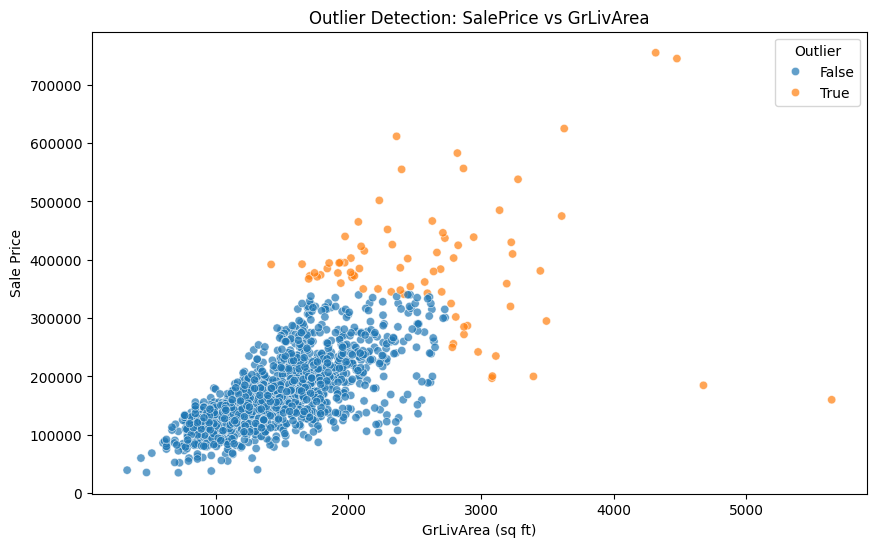

In [ ]:
# Výpočet IQR (interkvartilového rozpětí) pro prodejní cenu
Q1_price = df["SalePrice"].quantile(0.25)  # 1. kvartil (25 % nejnižších cen)
Q3_price = df["SalePrice"].quantile(0.75)  # 3. kvartil (75 % nejnižších cen)
IQR_price = Q3_price - Q1_price            # IQR = Q3 - Q1
lower_price = Q1_price - 1.5 * IQR_price   # dolní mez pro odlehlé hodnoty
upper_price = Q3_price + 1.5 * IQR_price   # horní mez pro odlehlé hodnoty

# Výpočet IQR pro obytnou plochu (GrLivArea)
Q1_area = df["GrLivArea"].quantile(0.25)   # 1. kvartil (25 % nejmenších ploch)
Q3_area = df["GrLivArea"].quantile(0.75)   # 3. kvartil (75 % nejmenších ploch)
IQR_area = Q3_area - Q1_area               # IQR = Q3 - Q1
lower_area = Q1_area - 1.5 * IQR_area      # dolní mez pro odlehlé hodnoty
upper_area = Q3_area + 1.5 * IQR_area      # horní mez pro odlehlé hodnoty

# Označení odlehlých hodnot (outlierů):
# True = dům vybočuje cenou nebo plochou mimo interval, False = normální hodnota
df["Outlier"] = (
    (df["SalePrice"] < lower_price) | (df["SalePrice"] > upper_price) |
    (df["GrLivArea"] < lower_area) | (df["GrLivArea"] > upper_area)
)

# Vykreslení scatter plotu:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df, 
    x="GrLivArea",     # osa X = obytná plocha domu
    y="SalePrice",     # osa Y = prodejní cena domu
    hue="Outlier",     # barva = označení outlieru (True/False)
    alpha=0.7          # průhlednost bodů
)

# Každý bod = jeden dům:
# - poloha = kombinace plochy a ceny
# - barva = jestli je to odlehlá hodnota (extrémní plocha/cena)
plt.title("Outlier Detection: SalePrice vs GrLivArea")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("Sale Price")
plt.show()


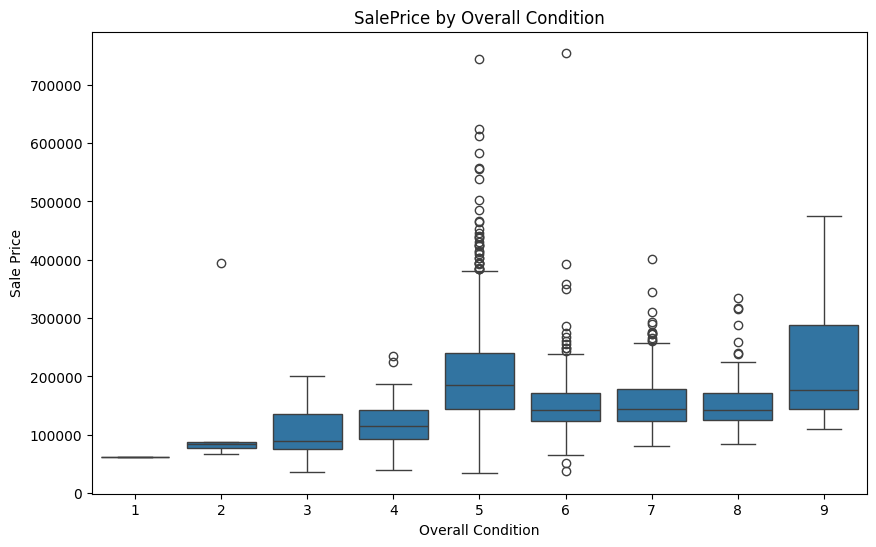

In [25]:
# Boxplot prodejní ceny (SalePrice) podle celkového stavu domu (OverallCond)

plt.figure(figsize=(10,6))

# Vykreslení boxplotu:
# - osa X = OverallCond (celkový stav domu, hodnocení kvality/stavu)
# - osa Y = SalePrice (prodejní cena domu)
sns.boxplot(data=df, x="OverallCond", y="SalePrice")

# Vysvětlení boxplotu:
# - Každý sloupec (box) = rozdělení cen pro domy s daným hodnocením stavu
# - Čára uvnitř boxu = medián (prostřední hodnota ceny)
# - Spodní a horní hrana boxu = 1. a 3. kvartil (Q1 a Q3)
# - "Vousy" (čáry z boxu ven) = rozsah hodnot bez odlehlých
# - Body mimo vousy = odlehlé hodnoty (outliery)

plt.title("SalePrice by Overall Condition")   # název grafu
plt.xlabel("Overall Condition")               # popis osy X
plt.ylabel("Sale Price")                      # popis osy Y
plt.show()
